In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [ ]:
import h5py
from pathlib import Path

dataset_dir = Path("data/emg2pose_dataset_mini")
fpath = dataset_dir / "2022-12-06-1670313600-e3096-cv-emg-pose-train@2-recording-1_left.hdf5"

with h5py.File(fpath, "r") as f:
    print("Keys in HDF5 file:", list(f.keys()))
    root_group = f["emg2pose"]
    print("Keys in 'emg2pose' group:", list(root_group.keys()))
    timeseries_dataset = root_group["timeseries"]
    print("Timeseries dataset shape:", timeseries_dataset.shape)
    print("Timeseries dataset dtype:", timeseries_dataset.dtype)

    print(f"Root attributes:", root_group.attrs.keys())
    print(f"Timeseries attributes:", timeseries_dataset.attrs.keys())

    print(f"EMG dataset shape: {timeseries_dataset['emg'].shape}")
    print(f"Joint angles dataset shape: {timeseries_dataset['joint_angles'].shape}")
    print(f"Time dataset shape: {timeseries_dataset['time'].shape}")
    print()
    print("root group attributes:")
    for k, v in root_group.attrs.items():
        print(f"{k}: {v}")



In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_emg2pose_metadata(csv_path):
    df = pd.read_csv(csv_path)

    print(f"--- emg2pose Metadata Analysis ---")
    print(f"Total Files (Runs): {len(df)}")
    print(f"Total Unique Users: {df['user'].nunique()}")
    print(f"Total Unique Stages: {df['stage'].nunique()}")

    # 1. Verify Redundancy / Logic
    # Check if 'split' matches 'generalization' expectations
    train_gen = df[df['split'] == 'train']['generalization'].unique()
    print(f"\nGeneralization types in TRAIN split: {train_gen}") 
    # Usually just 'none' or 'n/a' for training

    # 2. The Generalization Matrix (The "Heart" of the split)
    matrix = pd.crosstab(df['generalization'], df['split'])
    
    # 3. Visualization
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    # Plot A: How many files per generalization category
    sns.countplot(data=df, x='generalization', hue='split', ax=axes[0])
    axes[0].set_title("File Counts by Generalization & Split")
    
    # Plot B: Subject Distribution
    # We want to see how many users are 'held_out'
    user_status = df.groupby('user')['held_out_user'].first().value_counts()
    user_status.plot(kind='pie', autopct='%1.1f%%', ax=axes[1], labels=['In-Distribution', 'Held-Out User'])
    axes[1].set_title("User-Level Split")
    axes[1].set_ylabel("")

    plt.tight_layout()
    plt.show()

    # 4. Stage Specificity
    # Which stages are held out?
    held_out_stages = df[df['held_out_stage'] == True]['stage'].unique()
    print(f"\nTotal Held-out Stages: {len(held_out_stages)}")
    print(f"Sample Held-out Stages: {held_out_stages[:5]}")

    return df

In [ ]:
analyze_emg2pose_metadata("data/emg2pose_dataset_mini/metadata.csv")

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_emg2pose_structure(csv_path):
    df = pd.read_csv(csv_path)
    
    # 1. Sessions per User
    sessions_per_user = df.groupby('user')['session'].nunique()
    print(f"--- Session Distribution ---")
    print(f"Average Sessions per User: {sessions_per_user.mean():.2f}")
    print(f"Max Sessions: {sessions_per_user.max()} | Min Sessions: {sessions_per_user.min()}")

    # 2. Stage Consistency: Does every session have all stages?
    # Group by session and count unique stages
    stages_per_session = df.groupby('session')['stage'].nunique()
    total_stages = df['stage'].nunique()
    complete_sessions = (stages_per_session == total_stages).sum()
    
    print(f"\n--- Stage Consistency ---")
    print(f"Total Unique Stages in Dataset: {total_stages}")
    print(f"Sessions with ALL {total_stages} stages: {complete_sessions} / {len(stages_per_session)}")
    
    if complete_sessions < len(stages_per_session):
        missing = total_stages - stages_per_session.min()
        print(f"Warning: Some sessions are missing up to {missing} stages.")

    return df, sessions_per_user, stages_per_session



In [ ]:
df, sess_counts, stage_counts = analyze_emg2pose_structure("data/emg2pose_dataset_mini/metadata.csv")

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_emg2pose_metadata(csv_path):
    # Load metadata
    df = pd.read_csv(csv_path)
    
    # 1. Sessions per user Analysis
    sessions_per_user = df.groupby('user')['session'].nunique().reset_index()
    sessions_per_user.columns = ['user', 'session_count']
    
    print(f"--- User/Session Stats ---")
    print(f"Total Users: {df['user'].nunique()}")
    print(f"Average Sessions per User: {sessions_per_user['session_count'].mean():.2f}")
    print(f"Max Sessions: {sessions_per_user['session_count'].max()}")
    print(f"Min Sessions: {sessions_per_user['session_count'].min()}")

    # 2. Stage Consistency Check (Are sessions complete?)
    # Group by session and count unique stages
    stages_per_session = df.groupby('session')['stage'].nunique()
    total_stages = df['stage'].nunique() # Should be 29
    complete_sessions = (stages_per_session == total_stages).sum()
    
    print(f"\n--- Stage Consistency ---")
    print(f"Total Unique Stages in Dataset: {total_stages}")
    print(f"Sessions with ALL {total_stages} stages: {complete_sessions} / {len(stages_per_session)}")
    
    # Identify sessions with missing data
    if complete_sessions < len(stages_per_session):
        incomplete = stages_per_session[stages_per_session < total_stages]
        print(f"Incomplete Sessions found: {len(incomplete)}")
        print(f"Average stages in incomplete sessions: {incomplete.mean():.1f}")

    # --- Plotting ---
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    # A. Histogram: Number of sessions per user
    sns.histplot(sessions_per_user['session_count'], 
                 bins=np.arange(0.5, sessions_per_user['session_count'].max() + 1.5), 
                 ax=axes[0], color='skyblue', edgecolor='black')
    axes[0].set_title("Distribution of Sessions per User")
    axes[0].set_xlabel("Number of Sessions")
    axes[0].set_ylabel("Count of Users")
    axes[0].set_xticks(range(1, int(sessions_per_user['session_count'].max()) + 1))

    # B. Heatmap: Stages per User (Confusion Matrix style)
    # Pivot: Users (Y) vs Stages (X), values are the count of runs
    user_stage_pivot = pd.crosstab(df['user'], df['stage'])
    
    # We use a heatmap to show if any user is missing specific stages
    sns.heatmap(user_stage_pivot, ax=axes[1], cmap="YlGnBu", cbar_kws={'label': 'Run Count'})
    axes[1].set_title("User-Stage Completeness Heatmap")
    axes[1].set_xlabel("Stage Name")
    axes[1].set_ylabel("User ID")
    
    # Cleanup: Hide Y-ticks if there are too many users to read
    if len(user_stage_pivot) > 50:
        axes[1].set_yticks([])

    plt.tight_layout()
    plt.savefig('emg2pose_audit.png')
    plt.show()

    return df



In [ ]:
analyze_emg2pose_metadata("data/emg2pose_dataset_mini/metadata.csv")

In [3]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import re

def extract_dataset_metadata(hdf5_path, root_key):
    """
    Crawls a unified biosignal HDF5 file and flattens metadata into a DataFrame.
    """
    records = []
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            raise KeyError(f"Root key '{root_key}' not found in {hdf5_path}")
        
        root = f[root_key]
        for subj_id in tqdm(root.keys(), desc=f"Scanning {root_key}"):
            subj_group = root[subj_id]
            subj_meta = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                sess_meta = dict(sess_group.attrs)

                for run_key in sess_group.keys():
                    if not isinstance(sess_group[run_key], h5py.Group):
                        continue
                    
                    run_group = sess_group[run_key]
                    run_meta = dict(run_group.attrs)
                
                    # Signal metrics
                    emg_data = run_group['emg']
                    t, c = emg_data.shape
                    fs = run_group['emg'].attrs['sample_rate']
                    # fs = sess_meta.get('sample_rate', 200)
                    
                    # Combine metadata
                    record = {
                        **subj_meta,
                        **sess_meta,
                        **run_meta,
                        'subj_key': subj_id,
                        'sess_key': sess_id,
                        'run_key': run_key,
                        'num_samples': t,
                        'num_channels': c,
                        'duration_sec': t / fs,
                        'emg_mean': np.mean(emg_data),
                        'emg_std': np.std(emg_data)
                    }
                    records.append(record)
                
    df = pd.DataFrame(records)
    # Ensure participant_num is a sortable type (int if possible)
    # Participarn ID is often a string like "subject_01", so we can extract the numeric part for sorting
    try:
        regex = re.compile(r'\d+')
        df['participant_number'] = df['participant_id'].apply(lambda x: int(regex.search(str(x)).group()) if regex.search(str(x)) else x)
        df.sort_values('participant_number', inplace=True)
    except:
        pass
        
    return df

In [4]:
df = extract_dataset_metadata("data/emg2pose/emg2pose.hdf5", "emg2pose")

Scanning emg2pose: 100%|██████████| 1/1 [00:02<00:00,  2.20s/it]


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

class BiosignalAuditor:
    def __init__(self, df, dataset_name="Dataset"):
        self.df = df
        self.name = dataset_name.upper()
        # Filter out unlabelled for core distribution plots
        self.df_clean = df[df['stage'] != -1].copy()
        
        plt.style.use('seaborn-v0_8-muted')
        sns.set_context("talk")

    def run_full_audit(self):
        """Executes all visualization and statistical checks."""
        self.plot_overview()
        self.plot_length_leakage_check()
        self.print_summary()

    def plot_overview(self):
        fig, axes = plt.subplots(5, 2, figsize=(40, 50))
        plt.subplots_adjust(hspace=0.4)
            
        # 1. Class Distribution (Gesture ID)
        # This checks for "Label Imbalance"
        sns.countplot(data=self.df, x='stage', hue='inter_task_split', ax=axes[0,0])
        axes[0,0].set_title("Gesture Class Distribution (Intra-Session Split)")
        axes[0,0].tick_params(axis='x', rotation=45)


        sns.countplot(data=self.df, x='stage', hue='inter_subject_split', ax=axes[0,1])
        axes[0,1].set_title("Gesture Class Distribution (Inter-Subject Split)")
        axes[0,1].tick_params(axis='x', rotation=45)


        # 2. Duration Distribution
        sns.histplot(data=self.df_clean, x='duration_sec', hue='inter_task_split', multiple="stack", ax=axes[1,0])
        axes[1,0].set_title("Distribution of Trial Durations - Intra-session split (Seconds)")

        sns.histplot(data=self.df_clean, x='duration_sec', hue='inter_subject_split', multiple="stack", ax=axes[1,1])
        axes[1,1].set_title("Distribution of Trial Durations - Inter-subject split (Seconds)")

        # 3. Leakage Heatmap (Subject-to-Split Mapping)
        leak_table = pd.crosstab(self.df['participant_id'], self.df['inter_task_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,0])
        axes[2,0].set_title("Session Leakage Check")

        leak_table = pd.crosstab(self.df['participant_id'], self.df['inter_subject_split'])
        sns.heatmap(leak_table, annot=True, cbar=False, cmap='Blues', ax=axes[2,1])
        axes[2,1].set_title("Subject Leakage Check")


        # 4. 


        # 5. Signal Quality (Mean vs Std per Subject)
        sns.scatterplot(data=self.df_clean, x='emg_mean', y='emg_std', hue='participant_id', alpha=0.5, ax=axes[3,1])
        axes[3,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
        axes[3,1].get_legend().remove()


        # 6. Sex Distribution pie chart
        axes[4,0].pie(self.df_clean['sex'].value_counts(), labels=self.df_clean['sex'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2')) 
        axes[4,0].set_title("Gender Distribution")

        # 7. Handedness Distribution
        axes[4,1].pie(self.df_clean['handedness'].value_counts(), labels=self.df_clean['handedness'].unique(), autopct='%1.1f%%', colors=sns.color_palette('Set2'))
        axes[4,1].set_title("Handedness Distribution")


        plt.show()

    def plot_length_leakage_check(self):
        """Checks if gesture ID is perfectly predictable by signal duration."""
        plt.figure(figsize=(16, 6))
        sns.boxplot(data=self.df_clean.sort_values('stage'), x='stage', y='duration_sec', palette='husl')
        plt.axhline(self.df_clean['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
        plt.title(f"{self.name}: Signal Length Leakage Audit")
        plt.xticks(rotation=90 if self.df_clean['stage'].nunique() > 10 else 0)
        plt.legend()
        plt.show()

    def print_summary(self):
        print(f"\n{'='*40}\n{self.name} AUDIT REPORT\n{'='*40}")
        print(f"Total Subjects: {self.df['participant_id'].nunique()}")
        print(f"Total Trials:   {len(self.df)}")
        print(f"Total EMG Time: {self.df['duration_sec'].sum() / 3600:.2f} hours")
        
        for col in ['inter_task_split', 'inter_task_split', 'subject_split', 'inter_subject_split']:
            if col in self.df.columns:
                print(f"\nSplit Distribution ({col}):")
                print(self.df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        # Check for Inter-Subject Leakage
        subj_split_col = next((c for c in ['subject_split', 'inter_subject_split'] if c in self.df.columns), None)
        if subj_split_col:
            leak_check = self.df.groupby('participant_id')[subj_split_col].nunique()
            leaked = leak_check[leak_check > 1].index.tolist()
            if leaked:
                print(f"\n⚠️ WARNING: {len(leaked)} subjects found in multiple splits: {leaked[:5]}...")
            else:
                print("\n✅ Clean: No subject leakage detected across splits.")

In [ ]:
auditor = BiosignalAuditor(df, "emg2pose")
auditor.run_full_audit()

In [ ]:
def plot_global_amplitude_histogram(hdf5_path, root_key, n_runs_to_sample=50):
    """
    Plots a histogram of all raw EMG datapoints across a subset of runs.
    This reveals the statistical distribution (PDF) of the signal.
    """
    all_values = []
    n = 0
    with h5py.File(hdf5_path, 'r') as f:
        for subj_id in f[root_key].keys():
            subj_group = f[root_key][subj_id]
            for sess_id in subj_group.keys():
                sess_group = subj_group[sess_id]
                for run_key in sess_group.keys():
                    run_group = sess_group[run_key]
                    emg_data = run_group['emg'][:]
                    all_values.extend(emg_data.flatten())
                    n += 1
                    if n >= n_runs_to_sample:
                        break
    
    all_values = np.array(all_values)

    print(f"Maximum EMG Value: {all_values.max():.2f}")
    print(f"Minimum EMG Value: {all_values.min():.2f}")
    print(f"Mean EMG Value: {all_values.mean():.2f}")
    print(f"Standard Deviation: {all_values.std():.2f}")

    plt.figure(figsize=(12, 6))
    
    # Using a log scale for the Y-axis is often better for EMG 
    # because the 'Rest' zeros dominate the count.
    sns.histplot(all_values, kde=True, color='teal', binwidth=10)
    
    # plt.yscale('log') 
    # plt.ylim(0, None)  # Let the upper limit auto-adjust
    plt.xlim(-100, 100)
    plt.title(f"{root_key}: Global Amplitude Distribution (All Datapoints)")
    plt.xlabel("Amplitude (Normalized units)")
    plt.ylabel("Frequency (Log Scale)")
    plt.grid(True, which="both", ls="-", alpha=0.2)
    
    # Add vertical lines for standard deviations
    std = np.std(all_values)
    plt.axvline(std, color='orange', linestyle='--', label=f'1 Std ({std:.2f})')
    plt.axvline(-std, color='orange', linestyle='--')
    plt.legend()
    
    plt.show()

In [ ]:
plot_global_amplitude_histogram("data/emg2pose/emg2pose.hdf5", "emg2pose", n_runs_to_sample=100)

In [6]:
df = extract_dataset_metadata("/mnt/data/emg2pose_data/emg2pose.hdf5", "emg2pose")

Scanning emg2pose: 100%|██████████| 193/193 [47:12<00:00, 14.68s/it]


KeyError: 'sex'

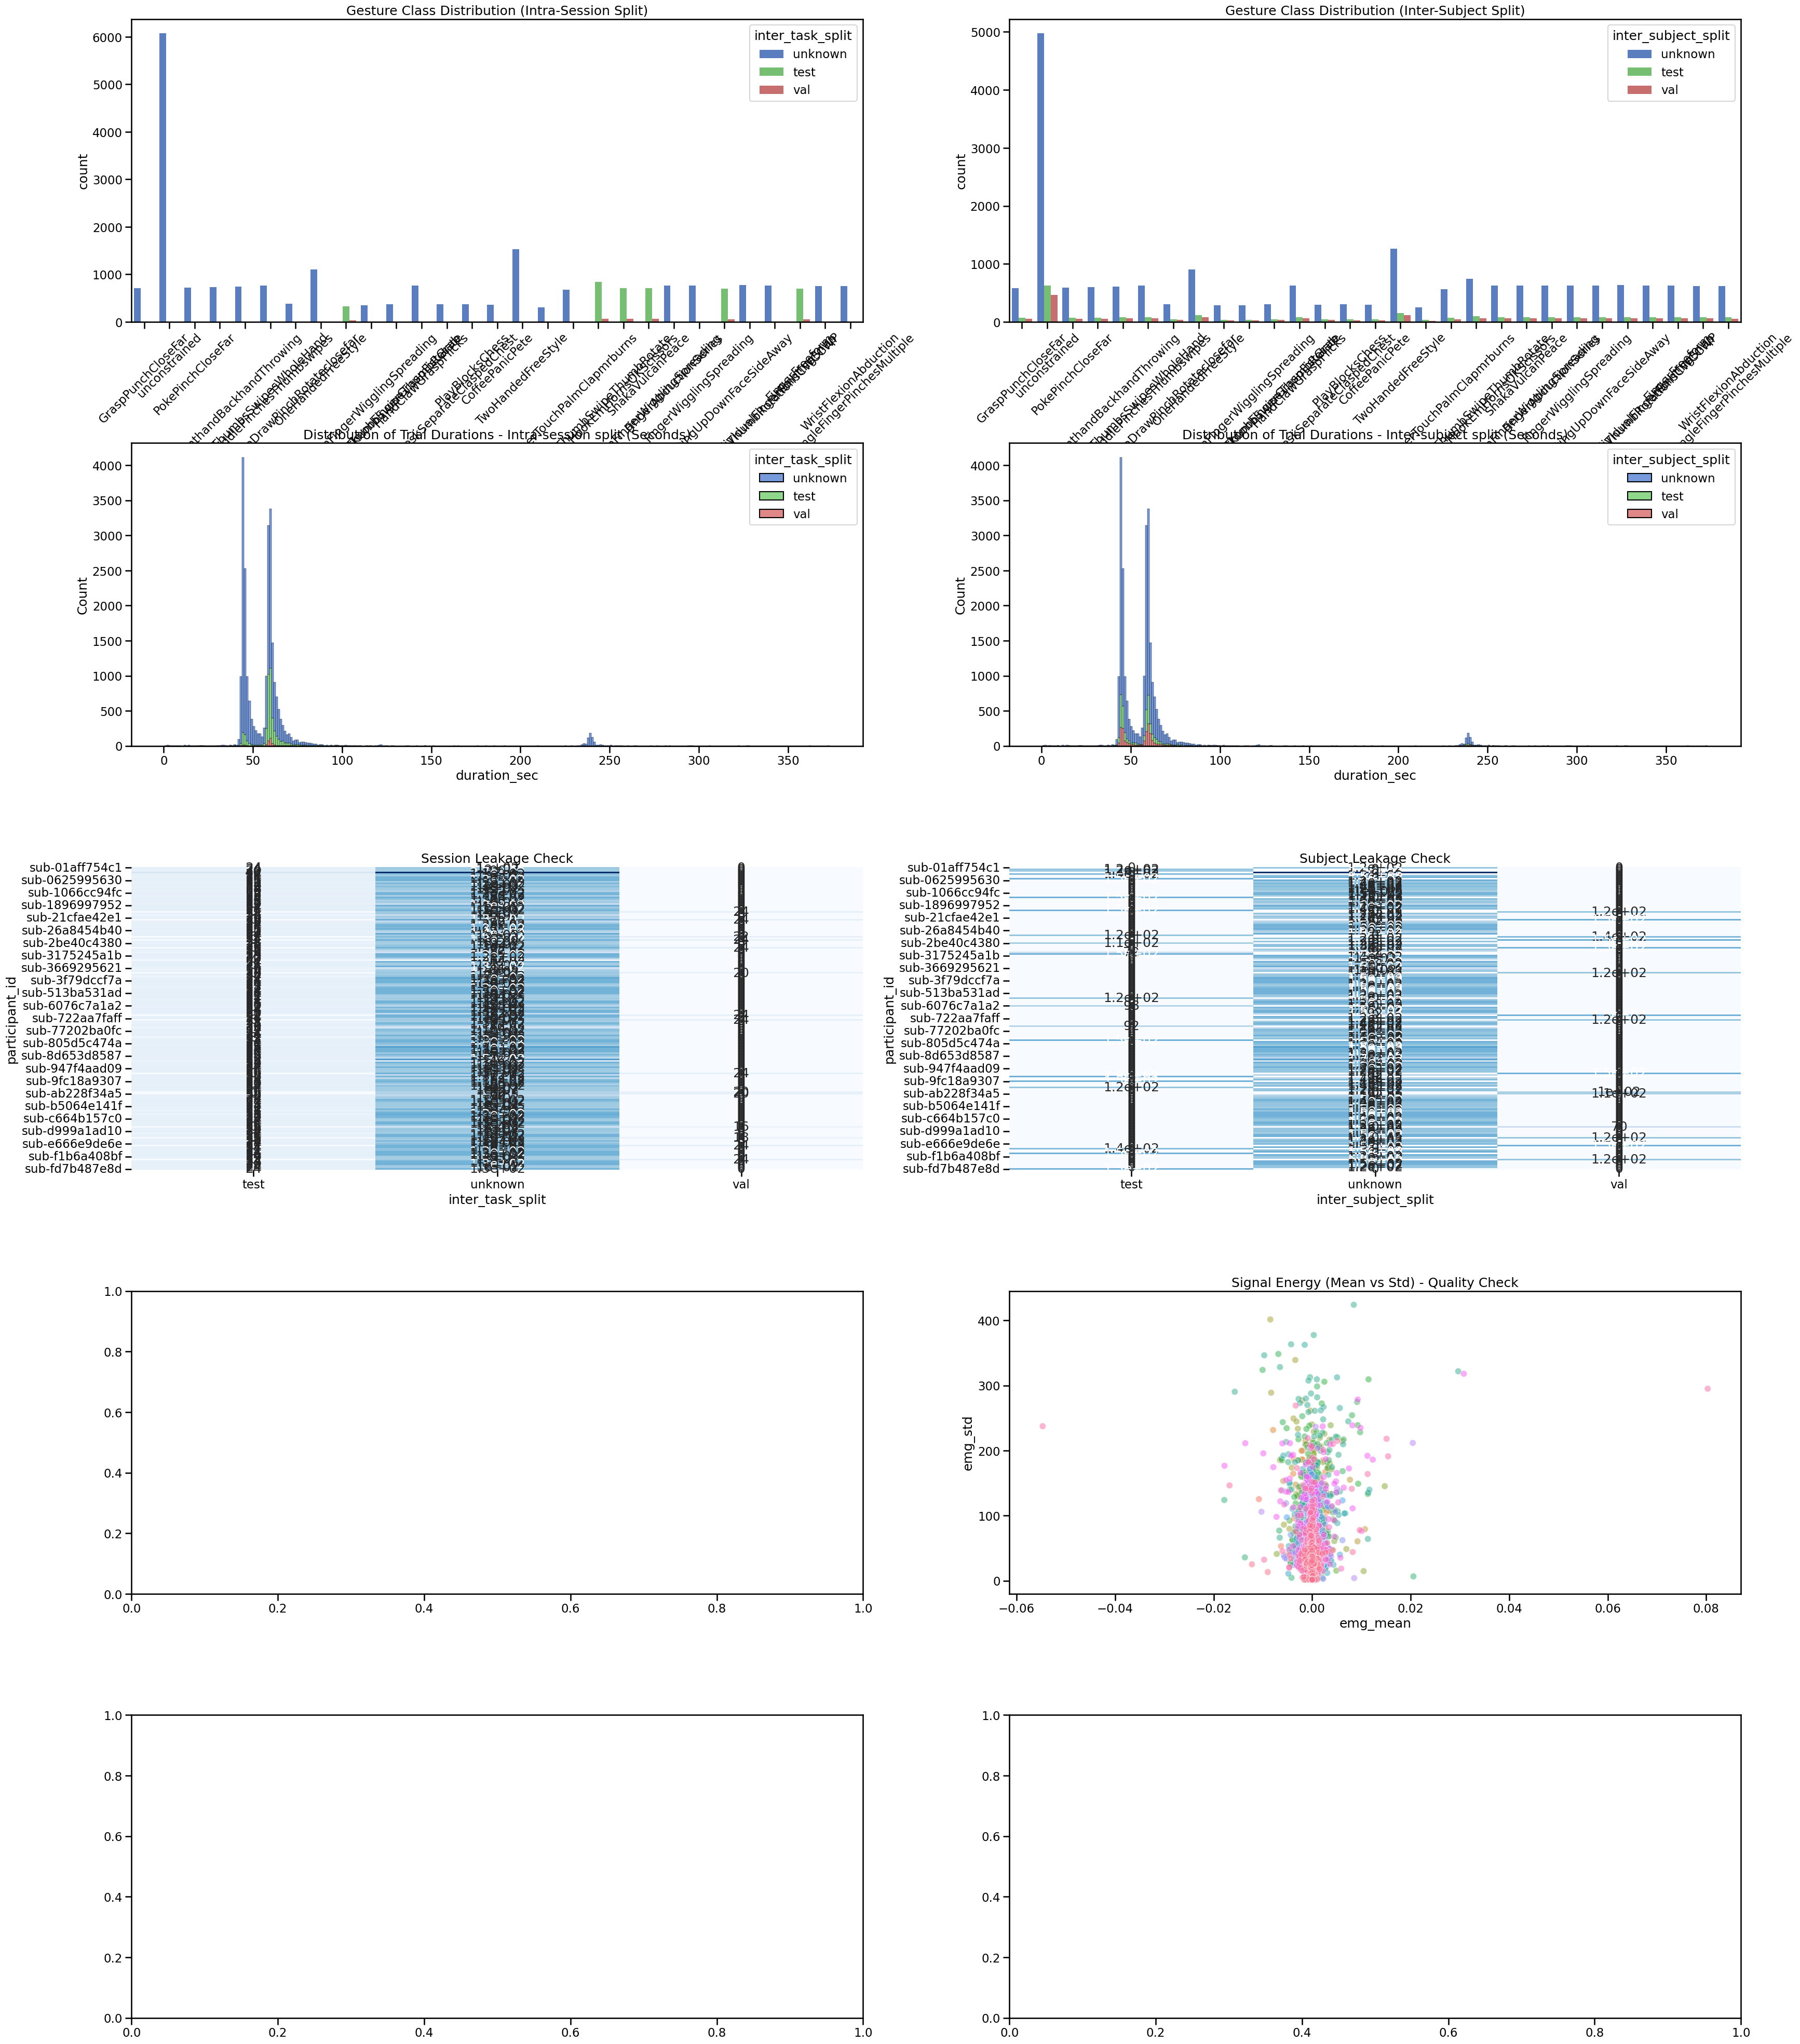

In [7]:
auditor = BiosignalAuditor(df, "emg2pose")
auditor.run_full_audit()

In [8]:
def encode_stage(stage_str):
    stage_to_idx = {
        'ThumbsUpDownThumbRotationsCWCCWP': 0,
        'HandClawGraspFlicks': 1,
        'ShakaVulcanPeace': 2,
        'HookEmHornsOKScissors': 3,
        'TwoHandedFreeStyle': 4,
        'unconstrained': 5,
        'OneHandedFreeStyle': 6,
        'CountingUpDownFaceSideAway': 7,
        'ThumbsSwipesWholeHand': 8,
        'FingerWigglingSpreading': 9,
        'FingerAbductionSeries': 10,
        'FingerPinchesSingleFingerPinchesMultiple': 11,
        'FingerFreeform': 12,
        'IndividualFingerPointingSnap': 13,
        'GraspPunchCloseFar': 14,
        'PokeDrawPinchRotateclosefar': 15,
        'AllFingerPinchesThumbSwipeThumbRotate': 16,
        'CountingUpDownFingerWigglingSpreading': 17,
        'IndexPinchesMiddlePinchesThumbswipes': 18,
        'DoorknobFingerGraspFistGrab': 19,
        'FastPongFronthandBackhandThrowing': 20,
        'HandDeskSeparateClaspedChest': 21,
        'PokePinchCloseFar': 22,
        'FingerTouchPalmClapmrburns': 23,
        'WristFlexionAbduction': 24,
        'PlayBlocksChess': 25,
        'CoffeePanicPete': 26,
        'HandOverHandAllFingerPinchesThumbSwipeThumbRotate': 27,
        'HandOverHandCountingUpDownFingerWigglingSpreading': 28
    }
    return stage_to_idx.get(stage_str, -1)  # Return -1 for unknown stages


In [ ]:
with h5py.File("/mnt/data/emg2pose_data/emg2pose.hdf5", 'r') as f:
    for subj_id in tqdm(f["emg2pose"].keys()):
        subj_group = f["emg2pose"][subj_id]
        for sess_id in subj_group.keys():
            sess_group = subj_group[sess_id]
            for run_key in sess_group.keys():
                run_group = sess_group[run_key]

                stage_str = run_group.attrs.get('stage', None)
                if stage_str is not None:
                    gesture_id = encode_stage(stage_str)
                    if gesture_id == -1:
                        print(f"Warning: Unrecognized stage '{stage_str}' in {subj_id}/{sess_id}/{run_key}")
                    run_group.attrs['gesture_id'] = gesture_id

  0%|          | 0/193 [00:00<?, ?it/s]


OSError: Unable to synchronously create attribute (no write intent on file)

In [1]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [2]:
import h5py
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
def plot_global_amplitude_histogram(hdf5_path, root_key, n_runs_to_sample=50):
    """
    Plots a histogram of all raw EMG datapoints across a subset of runs.
    This reveals the statistical distribution (PDF) of the signal.
    """
    all_values = []
    n = 0
    with h5py.File(hdf5_path, 'r') as f:
        for subj_id in f[root_key].keys():
            subj_group = f[root_key][subj_id]
            for sess_id in subj_group.keys():
                sess_group = subj_group[sess_id]
                for run_key in sess_group.keys():
                    print(f"Loading {subj_id}/{sess_id}/{run_key}...")
                    run_group = sess_group[run_key]
                    emg_data = run_group['emg'][:]
                    all_values.extend(emg_data.flatten())
                    n += 1
                    
                    if n >= n_runs_to_sample:
                        print(f"Sampled {n_runs_to_sample} runs, stopping further loading.")
                        break
                if n >= n_runs_to_sample:
                    break
            if n >= n_runs_to_sample:
                break
    
    all_values = np.array(all_values)

    plt.figure(figsize=(12, 6))
    
    # Using a log scale for the Y-axis is often better for EMG 
    # because the 'Rest' zeros dominate the count.
    sns.histplot(all_values, bins=100, kde=True, color='teal')
    
    plt.yscale('log') 
    plt.title(f"{root_key}: Global Amplitude Distribution (All Datapoints)")
    plt.xlabel("Amplitude (Normalized units)")
    plt.ylabel("Frequency (Log Scale)")
    plt.grid(True, which="both", ls="-", alpha=0.2)
    
    # Add vertical lines for standard deviations
    std = np.std(all_values)
    plt.axvline(std, color='orange', linestyle='--', label=f'1 Std ({std:.2f})')
    plt.axvline(-std, color='orange', linestyle='--')
    plt.legend()
    
    plt.show()

In [7]:
plot_global_amplitude_histogram("/mnt/data/emg2pose_data/emg2pose.hdf5", "emg2pose", n_runs_to_sample=2)

Loading sub-01aff754c1/ses-2022-10-18-1666080000-10a50-cv-emg-pose-demonstration@2/run-2022-10-18-1666080000-10a50-cv-emg-pose-demonstration@2-recording-10_left...
Loading sub-01aff754c1/ses-2022-10-18-1666080000-10a50-cv-emg-pose-demonstration@2/run-2022-10-18-1666080000-10a50-cv-emg-pose-demonstration@2-recording-10_right...
Sampled 2 runs, stopping further loading.
Loading sub-01aff754c1/ses-2022-10-18-1666080000-37d82-cv-emg-pose-demonstration@2/run-2022-10-18-1666080000-37d82-cv-emg-pose-demonstration@2-recording-10_left...
Sampled 2 runs, stopping further loading.
Loading sub-01aff754c1/ses-2022-10-18-1666080000-b1dd0-cv-emg-pose-train@2/run-2022-10-18-1666080000-b1dd0-cv-emg-pose-train@2-recording-10_left...
Sampled 2 runs, stopping further loading.
Loading sub-01aff754c1/ses-2022-10-18-1666080000-c5b4b-cv-emg-pose-train@2/run-2022-10-18-1666080000-c5b4b-cv-emg-pose-train@2-recording-10_left...
Sampled 2 runs, stopping further loading.
Loading sub-0219627c14/ses-2022-10-31-16672

KeyboardInterrupt: 